In [92]:
import pandas as pd
import requests
import numpy as np

In [4]:
random_state=2008
BASE='https://api.openf1.org/v1'

In [81]:
def _get_data(endpoint: str, **kwargs) -> pd.DataFrame:
    params = {k: v for k, v in kwargs.items() if v is not None}

    response = requests.get(
        f"{BASE}/{endpoint}",
        params=params,
        timeout=120,
    )
    response.raise_for_status()

    return pd.DataFrame(response.json())


def get_sessions(**kwargs) -> pd.DataFrame:
    kwargs.setdefault("year", 2026)

    df = _get_data("sessions", **kwargs)

    for col in ["date_start", "date_end"]:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], utc=True).dt.tz_localize(None)

    return df


def get_drivers(**kwargs) -> pd.DataFrame:
    return _get_data("drivers", **kwargs)


def get_starting_grid(**kwargs) -> pd.DataFrame:
    return _get_data("starting_grid", **kwargs)


def get_laps(**kwargs) -> pd.DataFrame:
    df = _get_data("laps", **kwargs)

    if "date_start" in df.columns:
        df["date_start"] = pd.to_datetime(
            df["date_start"], utc=True
        ).dt.tz_localize(None)

    return df


def get_car_data(**kwargs) -> pd.DataFrame:
    df = _get_data("car_data", **kwargs)

    if "date" in df.columns:
        df["date"] = pd.to_datetime(
            df["date"], utc=True, format='ISO8601'
        ).dt.tz_localize(None)

    return df


def get_location(**kwargs) -> pd.DataFrame:
    df = _get_data("location", **kwargs)

    if "date" in df.columns:
        df["date"] = pd.to_datetime(
            df["date"], utc=True, format='ISO8601'
        ).dt.tz_localize(None)

    return df


def get_position(**kwargs) -> pd.DataFrame:
    df=_get_data('position', **kwargs)

    if 'date' in df.columns:
        df["date"] = pd.to_datetime(
            df["date"], utc=True, format='ISO8601'
        ).dt.tz_localize(None)

    return df


def get_stints_data(**kwargs) -> pd.DataFrame:
    return _get_data("stints", **kwargs)


def get_pits_data(**kwargs) -> pd.DataFrame:
    df= _get_data('pit', **kwargs)

    if "date" in df.columns:
        df["date"] = pd.to_datetime(
            df["date"], utc=True, format='ISO8601'
        ).dt.tz_localize(None)

    return df


def get_session_result(**kwargs) -> pd.DataFrame:
    return _get_data("session_result", **kwargs)

In [40]:
sessions_2026=get_sessions(year=2026)
sessions_2026_df=pd.DataFrame(sessions_2026)
sessions_2026_df.head()

,session_key,session_type,session_name,date_start,date_end,meeting_key,circuit_key,circuit_short_name,country_key,country_code,country_name,location,gmt_offset,year,is_cancelled
0,11465,Practice,Day 1,2026-02-11 07:00:00,2026-02-11 16:00:00,1304,63,Sakhir,36,BRN,Bahrain,Bahrain,03:00:00,2026,False
1,11466,Practice,Day 2,2026-02-12 07:00:00,2026-02-12 16:00:00,1304,63,Sakhir,36,BRN,Bahrain,Bahrain,03:00:00,2026,False
2,11467,Practice,Day 3,2026-02-13 07:00:00,2026-02-13 16:00:00,1304,63,Sakhir,36,BRN,Bahrain,Bahrain,03:00:00,2026,False
3,11470,Practice,Day 1,2026-02-18 07:00:00,2026-02-18 16:00:00,1305,63,Sakhir,36,BRN,Bahrain,Bahrain,03:00:00,2026,False
4,11469,Practice,Day 2,2026-02-19 07:00:00,2026-02-19 16:00:00,1305,63,Sakhir,36,BRN,Bahrain,Bahrain,03:00:00,2026,False


In [42]:
CIRCUIT_SHORT_NAME='Baku'

In [43]:
sessions_filtered_by_circuit = sessions_2026_df[sessions_2026_df['circuit_short_name']==CIRCUIT_SHORT_NAME]
sessions_filtered_by_circuit

,session_key,session_type,session_name,date_start,date_end,meeting_key,circuit_key,circuit_short_name,country_key,country_code,country_name,location,gmt_offset,year,is_cancelled
86,11370,Practice,Practice 1,2026-09-24 08:30:00,2026-09-24 09:30:00,1295,144,Baku,30,AZE,Azerbaijan,Baku,04:00:00,2026,False
87,11371,Practice,Practice 2,2026-09-24 12:00:00,2026-09-24 13:00:00,1295,144,Baku,30,AZE,Azerbaijan,Baku,04:00:00,2026,False
88,11372,Practice,Practice 3,2026-09-25 08:30:00,2026-09-25 09:30:00,1295,144,Baku,30,AZE,Azerbaijan,Baku,04:00:00,2026,False
89,11373,Qualifying,Qualifying,2026-09-25 12:00:00,2026-09-25 13:00:00,1295,144,Baku,30,AZE,Azerbaijan,Baku,04:00:00,2026,False
90,11377,Race,Race,2026-09-26 11:00:00,2026-09-26 13:00:00,1295,144,Baku,30,AZE,Azerbaijan,Baku,04:00:00,2026,False


In [44]:
quals_filtered_by_circuit=sessions_filtered_by_circuit[sessions_filtered_by_circuit['session_type']=='Qualifying']
races_filtered_by_circuit=sessions_filtered_by_circuit[sessions_filtered_by_circuit['session_type']=='Race']

if len(quals_filtered_by_circuit):
    quals_session_key=quals_filtered_by_circuit.iloc[0]['session_key']
else:
    print('Отсутствуют квалификации')

if len(races_filtered_by_circuit):
    race_session_key=races_filtered_by_circuit.iloc[0]['session_key']
else:
    print('Отсутствуют гонки')

In [45]:
drivers_data=get_drivers(session_key=race_session_key)

drivers_data.head()

,meeting_key,session_key,driver_number,broadcast_name,full_name,name_acronym,team_name,team_colour,first_name,last_name,headshot_url,country_code
0,1295,11377,1,L NORRIS,Lando NORRIS,NOR,McLaren,F47600,Lando,Norris,https://media.formula1.com/d_driver_fallback_i...,None
1,1295,11377,3,M VERSTAPPEN,Max VERSTAPPEN,VER,Red Bull Racing,4781D7,Max,Verstappen,https://media.formula1.com/d_driver_fallback_i...,None
2,1295,11377,5,G BORTOLETO,Gabriel BORTOLETO,BOR,Audi,F50537,Gabriel,Bortoleto,https://media.formula1.com/d_driver_fallback_i...,None
3,1295,11377,6,I HADJAR,Isack HADJAR,HAD,Red Bull Racing,4781D7,Isack,Hadjar,https://media.formula1.com/d_driver_fallback_i...,None
4,1295,11377,10,P GASLY,Pierre GASLY,GAS,Alpine,00A1E8,Pierre,Gasly,https://media.formula1.com/d_driver_fallback_i...,None


In [46]:
DRIVER_NUMBER=1

In [47]:
start_grid_df=get_starting_grid(session_key=quals_session_key)
start_grid_df.head()

,position,driver_number,lap_duration,meeting_key,session_key
0,1,63,102.526,1295,11373
1,2,16,103.363,1295,11373
2,3,81,103.364,1295,11373
3,4,6,103.500,1295,11373
4,5,1,103.672,1295,11373


In [48]:
laps_df_driver1=get_laps(session_key=race_session_key, driver_number=DRIVER_NUMBER)
laps_df_driver1.head()

,meeting_key,session_key,driver_number,lap_number,date_start,duration_sector_1,duration_sector_2,duration_sector_3,i1_speed,i2_speed,is_pit_out_lap,lap_duration,segments_sector_1,segments_sector_2,segments_sector_3,st_speed
0,1295,11377,1,1,2026-09-26 11:03:50.711,44.260,45.326,25.270,184.0,196.0,False,114.856,"[None, 2049, 2049, 2049, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2051, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...",328.0
1,1295,11377,1,2,2026-09-26 11:05:45.567,39.575,45.259,25.368,183.0,198.0,False,110.202,"[2049, 2049, 2049, 2048, 2049, 2049, 2049, 2048]","[2049, 2048, 2049, 2049, 2049, 2049, 2049, 204...","[2048, 2048, 2048, 2051, 2048, 2048, 2048, 204...",323.0
2,1295,11377,1,3,2026-09-26 11:07:35.802,40.277,45.170,25.472,177.0,205.0,False,110.919,"[2048, 2049, 2048, 2048, 2048, 2048, 2049, 2048]","[2048, 2048, 2049, 2048, 2048, 2048, 2048, 204...","[2048, 2048, 2048, 2048, 2048, 2048, 2048, 2048]",325.0
3,1295,11377,1,4,2026-09-26 11:09:26.643,39.242,44.847,25.388,185.0,200.0,False,109.477,"[None, 2049, 2049, 2048, 2048, 2049, 2049, 2049]","[2049, 2048, 2049, 2051, 2049, 2048, 2049, 204...","[2048, 2048, 2048, 2048, 2048, 2049, 2049, 204...",330.0
4,1295,11377,1,5,2026-09-26 11:11:16.231,39.028,44.642,25.467,187.0,200.0,False,109.137,"[None, 2049, 2049, 2048, 2049, 2049, 2049, 2048]","[2049, 2048, 2049, 2048, 2048, 2048, 2048, 204...","[2048, 2048, 2048, 2048, 2048, 2048, 2048, 204...",327.0


In [82]:
first_lap_start=laps_df_driver1.iloc[0]['date_start']
first_lap_start

Timestamp('2026-09-26 11:03:50.711000')

In [84]:
position_df_driver1=get_position(session_key=race_session_key, driver_number=DRIVER_NUMBER)
position_df_driver1

,date,session_key,meeting_key,driver_number,position
0,2026-09-26 10:07:06.143,11377,1295,1,5
1,2026-09-26 11:04:04.556,11377,1295,1,4
2,2026-09-26 11:07:35.489,11377,1295,1,5
3,2026-09-26 11:08:01.328,11377,1295,1,6
4,2026-09-26 11:32:59.978,11377,1295,1,7
5,2026-09-26 11:56:40.711,11377,1295,1,8
6,2026-09-26 11:56:43.749,11377,1295,1,9
7,2026-09-26 11:59:04.577,11377,1295,1,10
8,2026-09-26 12:01:31.880,11377,1295,1,9
9,2026-09-26 12:11:31.680,11377,1295,1,7


In [67]:
car_data_df_driver1=get_car_data(session_key=race_session_key, driver_number=DRIVER_NUMBER)

car_data_df_driver1=car_data_df_driver1[car_data_df_driver1['date']>=first_lap_start]
car_data_df_driver1.head()

,date,session_key,meeting_key,speed,n_gear,throttle,brake,drs,driver_number,rpm
12705,2026-09-26 11:03:50.921,11377,1295,0,1,28,100,None,1,12291
12706,2026-09-26 11:03:51.361,11377,1295,10,1,27,0,None,1,9955
12707,2026-09-26 11:03:51.561,11377,1295,16,1,26,0,None,1,8555
12708,2026-09-26 11:03:51.761,11377,1295,23,1,27,0,None,1,7155
12709,2026-09-26 11:03:52.041,11377,1295,32,1,29,0,None,1,6090


In [68]:
location_df_driver1=get_location(session_key=race_session_key, driver_number=DRIVER_NUMBER)

location_df_driver1=location_df_driver1[location_df_driver1['date']>=first_lap_start]
location_df_driver1.head()

,date,session_key,y,meeting_key,x,z,driver_number
12958,2026-09-26 11:03:50.792,11377,-382,1295,1570,-244,1
12959,2026-09-26 11:03:51.072,11377,-382,1295,1570,-244,1
12960,2026-09-26 11:03:51.232,11377,-382,1295,1570,-244,1
12961,2026-09-26 11:03:51.452,11377,-380,1295,1575,-244,1
12962,2026-09-26 11:03:51.732,11377,-375,1295,1587,-244,1


In [49]:
stints_df_driver1=get_stints_data(session_key=race_session_key, driver_number=DRIVER_NUMBER)
stints_df_driver1.head()

,meeting_key,session_key,stint_number,driver_number,lap_start,lap_end,compound,tyre_age_at_start
0,1295,11377,1,1,1,30,MEDIUM,0
1,1295,11377,2,1,31,35,SOFT,0


In [64]:
pits_df_driver1=get_pits_data(session_key=race_session_key, driver_number=DRIVER_NUMBER)
pits_df_driver1.head()

,date,session_key,pit_duration,lane_duration,driver_number,stop_duration,lap_number,meeting_key
0,2026-09-26 11:59:06.752,11377,20.8,20.8,1,None,30,1295


In [60]:
session_result_df=get_session_result(session_key=race_session_key)
session_result_df.head()

,position,driver_number,number_of_laps,points,dnf,dns,dsq,duration,gap_to_leader,meeting_key,session_key
0,1.0,63,51,25.0,False,False,False,5882.143,0.000,1295,11377
1,2.0,3,51,18.0,False,False,False,5882.339,0.196,1295,11377
2,3.0,6,51,15.0,False,False,False,5892.847,10.704,1295,11377
3,4.0,16,51,12.0,False,False,False,5896.279,14.136,1295,11377
4,5.0,12,51,10.0,False,False,False,5896.655,14.512,1295,11377


In [94]:
print(session_result_df[session_result_df['driver_number']==DRIVER_NUMBER].iloc[0]['position'])

nan


In [96]:
type(session_result_df[session_result_df['driver_number']==DRIVER_NUMBER].iloc[0]['position'])

numpy.float64

In [98]:
if pd.notna(session_result_df[session_result_df['driver_number']==DRIVER_NUMBER].iloc[0]['position']):
    print(1)

In [87]:
laps.tail()

,meeting_key,session_key,driver_number,lap_number,date_start,duration_sector_1,duration_sector_2,duration_sector_3,i1_speed,i2_speed,is_pit_out_lap,lap_duration,segments_sector_1,segments_sector_2,segments_sector_3,st_speed,date_end,position_start
31,1295,11377,1,32,2026-09-26 12:01:32.116000+00:00,47.071,55.916,29.343,115.0,177.0,False,132.330,"[2048, 2048, 2048, 2048, 2048, 2048, 2048, 2048]","[2048, 2048, 2048, 2048, 2048, 2048, 2048, 204...","[2048, 2048, 2048, 2048, 2048, 2048, 2048, 204...",281.0,2026-09-26 12:03:44.337000+00:00,9
32,1295,11377,1,33,2026-09-26 12:03:44.337000+00:00,44.949,66.127,37.941,118.0,134.0,False,149.017,"[None, 2048, 2048, 2048, 2048, 2048, 2048, 2048]","[2048, 2048, 2048, 2048, 2048, 2048, 2048, 204...","[2048, 2048, 2048, 2048, 2048, 2048, 2048, 204...",203.0,2026-09-26 12:06:13.398000+00:00,9
33,1295,11377,1,34,2026-09-26 12:06:13.398000+00:00,63.746,62.299,38.412,166.0,185.0,False,164.457,"[None, 2048, 2048, 2048, 2048, 2048, 2048, 2048]","[2048, 2048, 2048, 2048, 2048, 2048, 2048, 204...","[2048, 2048, 2048, 2048, 2048, 2048, 2048, 204...",234.0,2026-09-26 12:08:57.837000+00:00,9
34,1295,11377,1,35,2026-09-26 12:08:57.837000+00:00,51.791,63.079,34.676,160.0,145.0,False,149.546,"[None, 2048, 2048, 2048, 2048, 2048, 2048, 2048]","[2048, 2048, 2048, 2048, 2048, 2048, 2048, 204...","[2048, 2048, 2048, 2048, 2048, 2048, 2048, 204...",233.0,2026-09-26 12:11:27.558000+00:00,9
35,1295,11377,1,36,2026-09-26 12:11:27.558000+00:00,NaN,NaN,NaN,NaN,NaN,False,NaN,"[None, 0, 0, 0, 0, 0, 0, 0]",None,None,NaN,NaT,9


In [ ]:
import pandas as pd

laps = laps_df_driver1.copy()
positions = position_df_driver1.copy()

# 1. Преобразуем даты
laps["date_start"] = pd.to_datetime(laps["date_start"], utc=True)
positions["date"] = pd.to_datetime(positions["date"], utc=True)

# 2. Сортируем
laps = laps.sort_values("date_start").reset_index(drop=True)
positions = positions.sort_values("date")

# 3. Вычисляем конец каждого круга
laps["date_end"] = laps["date_start"].shift(-1)

# Для последнего круга используем его продолжительность
laps.loc[laps.index[-1], "date_end"] = (
    laps.iloc[-1]["date_start"]
    + pd.to_timedelta(laps.iloc[-1]["lap_duration"], unit="s")
)

# 4. Позиция на старте круга
laps["position_start"] = pd.merge_asof(
    laps[["date_start"]],
    positions[["date", "position"]],
    left_on="date_start",
    right_on="date",
    direction="backward"
)["position"].to_numpy()

# 5. Позиция в конце круга
laps["position_end"] = pd.merge_asof(
    laps[["date_end"]],
    positions[["date", "position"]],
    left_on="date_end",
    right_on="date",
    direction="backward"
)["position"].to_numpy()

# 6. Изменение позиции
laps["position_delta"] = (
    laps["position_start"] - laps["position_end"]
)

laps[[
    "lap_number",
    "position_start",
    "position_end",
    "position_delta"
]]

ValueError: Merge keys contain null values on left side

In [ ]:
# session_result_df

In [72]:
from datetime import datetime

datetime.now()

datetime.datetime(2026, 10, 21, 20, 20, 19, 559377)

In [74]:
sessions_2026_df_filtered_now = sessions_2026_df[sessions_2026_df['date_start']<=datetime.now()]

races_2026_df_filtered_now = sessions_2026_df_filtered_now[sessions_2026_df_filtered_now['session_type']=='Race']
races_2026_df_filtered_now['circuit_short_name']

10             Melbourne
13              Shanghai
15              Shanghai
20                Suzuka
25                Sakhir
30                Jeddah
33                 Miami
35                 Miami
38              Montreal
40              Montreal
45           Monte Carlo
50             Catalunya
55             Spielberg
58           Silverstone
60           Silverstone
65     Spa-Francorchamps
70           Hungaroring
73             Zandvoort
75             Zandvoort
80                 Monza
85               Madring
90                  Baku
95          Kuala Lumpur
98             Singapore
100            Singapore
Name: circuit_short_name, dtype: object

In [118]:
quals_2026_df_filtered_now = sessions_2026_df_filtered_now[sessions_2026_df_filtered_now['session_type']=='Qualifying']
quals_2026_df_filtered_now

,session_key,session_type,session_name,date_start,date_end,meeting_key,circuit_key,circuit_short_name,country_key,country_code,country_name,location,gmt_offset,year,is_cancelled
9,11230,Qualifying,Qualifying,2026-03-07 05:00:00,2026-03-07 06:00:00,1279,10,Melbourne,5,AUS,Australia,Melbourne,11:00:00,2026,False
12,11236,Qualifying,Sprint Qualifying,2026-03-13 07:30:00,2026-03-13 08:14:00,1280,49,Shanghai,53,CHN,China,Shanghai,08:00:00,2026,False
14,11241,Qualifying,Qualifying,2026-03-14 07:00:00,2026-03-14 08:00:00,1280,49,Shanghai,53,CHN,China,Shanghai,08:00:00,2026,False
19,11249,Qualifying,Qualifying,2026-03-28 06:00:00,2026-03-28 07:00:00,1281,46,Suzuka,4,JPN,Japan,Suzuka,09:00:00,2026,False
24,11257,Qualifying,Qualifying,2026-04-11 16:00:00,2026-04-11 17:00:00,1282,63,Sakhir,36,BRN,Bahrain,Sakhir,03:00:00,2026,True
29,11265,Qualifying,Qualifying,2026-04-18 17:00:00,2026-04-18 18:00:00,1283,149,Jeddah,153,KSA,Saudi Arabia,Jeddah,03:00:00,2026,True
32,11271,Qualifying,Sprint Qualifying,2026-05-01 20:30:00,2026-05-01 21:14:00,1284,151,Miami,19,USA,United States,Miami Gardens,-04:00:00,2026,False
34,11276,Qualifying,Qualifying,2026-05-02 20:00:00,2026-05-02 21:00:00,1284,151,Miami,19,USA,United States,Miami Gardens,-04:00:00,2026,False
37,11282,Qualifying,Sprint Qualifying,2026-05-22 20:30:00,2026-05-22 21:14:00,1285,23,Montreal,46,CAN,Canada,Montréal,-04:00:00,2026,False
39,11287,Qualifying,Qualifying,2026-05-23 20:00:00,2026-05-23 21:00:00,1285,23,Montreal,46,CAN,Canada,Montréal,-04:00:00,2026,False


In [119]:
get_starting_grid(session_key=11257)

HTTPError: 404 Client Error: Not Found for url: https://api.openf1.org/v1/starting_grid?session_key=11257

In [76]:
import os
from pathlib import Path

In [ ]:
working_directory=Path.cwd() / 'storage'

working_directory.mkdir(exist_ok=True)

In [120]:
from time import sleep
from tqdm import tqdm


data={
    'driver_number': [],
    'session_key': [],
    'start_position': [],
    'finish_position': [],
}


for cirquit_short_name in tqdm(races_2026_df_filtered_now['circuit_short_name']):
    sessions_filtered_by_circuit = sessions_2026_df[sessions_2026_df['circuit_short_name']==cirquit_short_name]

    quals_filtered_by_circuit=sessions_filtered_by_circuit[sessions_filtered_by_circuit['session_type']=='Qualifying']
    races_filtered_by_circuit=sessions_filtered_by_circuit[sessions_filtered_by_circuit['session_type']=='Race']

    if len(quals_filtered_by_circuit) and not quals_filtered_by_circuit.iloc[0]['is_cancelled']:
        quals_session_key=quals_filtered_by_circuit.iloc[0]['session_key']
    else:
        print('Отсутствуют квалификации')
        continue

    if len(races_filtered_by_circuit) and not races_filtered_by_circuit.iloc[0]['is_cancelled']:
        race_session_key=races_filtered_by_circuit.iloc[0]['session_key']
    else:
        print('Отсутствуют гонки')
        continue

    session_start_grid=get_starting_grid(session_key=quals_session_key)
    session_result_df=get_session_result(session_key=race_session_key)

    drivers_data=get_drivers(session_key=race_session_key)

    for driver_number in drivers_data['driver_number']:
        driver_result_start=session_start_grid[session_start_grid['driver_number']==driver_number].iloc[0]['position']
        driver_result_finish=session_result_df[session_result_df['driver_number']==driver_number].iloc[0]['position']

        if pd.isna(driver_result_finish):
            continue

        data['driver_number'].append(driver_number)
        data['session_key'].append(race_session_key)
        data['start_position'].append(driver_result_start)
        data['finish_position'].append(driver_result_finish)
        sleep(1)

        # print(cirquit_short_name, driver_number)

        # driver_laps_df=get_laps(session_key=race_session_key, driver_number=driver_number)

        # filename=f'{cirquit_short_name}_{driver_number}_2026.csv'
        # driver_laps_df.to_csv(working_directory/filename)

  0%|          | 0/25 [00:00<?, ?it/s]

 16%|█▌        | 4/25 [01:19<07:07, 20.37s/it]

Отсутствуют квалификации
Отсутствуют квалификации


100%|██████████| 25/25 [08:28<00:00, 20.34s/it]


In [121]:
res=pd.DataFrame(data)
res.head()

,driver_number,session_key,start_position,finish_position
0,1,11234,6.0,5.0
1,3,11234,20.0,6.0
2,5,11234,10.0,9.0
3,10,11234,14.0,10.0
4,11,11234,18.0,16.0


In [122]:
res.shape

(430, 4)

In [126]:
res[['start_position', 'finish_position']].corr()

,start_position,finish_position
start_position,1.000000,0.832832
finish_position,0.832832,1.000000


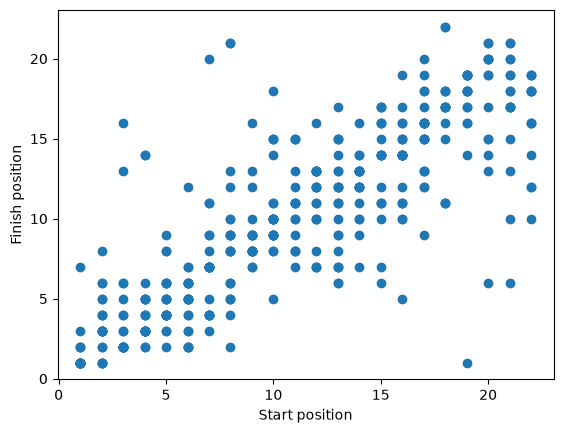

In [123]:
import matplotlib.pyplot as plt


plt.scatter(res['start_position'], res['finish_position'])

plt.xlabel('Start position')
plt.ylabel('Finish position')
plt.show()

In [124]:
from scipy import stats


s=stats.spearmanr(res['start_position'], res['finish_position'])

In [125]:
s.statistic, s.pvalue

(np.float64(0.8410880495155356), np.float64(2.7174741364060565e-116))